# Import packages and figure settings

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from skimage.measure import marching_cubes
import datetime
from pyproj import Transformer, Geod
import pandas as pd
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from mpl_toolkits.basemap import Basemap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from windrose import WindroseAxes
from scipy.integrate import cumulative_trapezoid
from skimage import measure, draw
from scipy.interpolate import RegularGridInterpolator
from scipy import ndimage,interpolate
from scipy.signal import find_peaks
from matplotlib.ticker import FormatStrFormatter
from shapely import Point, unary_union
import matplotlib.gridspec as gridspec
import rasterio.features
from scipy.optimize import minimize
from scipy.signal import correlate
from scipy.interpolate import CubicSpline
from scipy.optimize import  NonlinearConstraint
from scipy.ndimage import gaussian_filter1d, gaussian_filter
from scipy.optimize import curve_fit
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'Arial' # Choose a nice font here
plt.rcParams['font.size'] = 12 # standard font size
plt.rcParams['mathtext.fontset'] ='dejavusans'
plt.rcParams['mathtext.rm'] = 'Arial'
plt.rcParams['mathtext.it'] = 'Arial'

# Parameters

In [2]:
kap  = 0.41 # von karman constant
rhos_ws = 2320 # density gypsum
rhos_tk = 2650 # density quartz
rhof = 1.225 # density air
grav = 9.81 # gravity
z00  = 1e-3 # roughness length from Gadal et al. 2020 (White Sands) and Ren et al. 2024 (Taklamakan)
d = 2e-4 # particle diameter - representive
nu = 1e-5 # viscocity - representive
phi_ws = 1-0.27 # Porosity: Gunn et al. 2020 GRL (0.28); Pelletier 2015 JGR:ES (0.23-0.30)
phi_tk = 1-0.38 # Pye and Tsoar 2009, the porosity of quartz dune sands is approximately 38%.
d_tk = 160e-6 # particle diameter - Taklamakan
d_ws = 400e-6 # particle diameter - White Sands

# Functions

In [3]:
# all functions in this block used to calculate wind velocity over terrain based on the stress perturbation theory
def get_ab(Rei,Re_di):
 
    ReiF   = True
    if not isinstance(Rei, np.ndarray):
        if type(Rei)==list:
            Rei    = np.array(Rei)
        else:
            Rei    = np.array([Rei])
            ReiF   = False            
    Re_diF = True
    if not isinstance(Re_di, np.ndarray):
        if type(Re_di)==list:
            Re_di  = np.array(Re_di)
        else:
            Re_di  = np.array([Re_di])
            Re_diF = False

    Re_d = np.logspace(-2,4, 60+1) # Re for saved solutions
    Re   = np.logspace(-2,8,100+1) # Re_d for saved solutions
    ab   = np.loadtxt('/Users/ylin0188/Desktop/code box/dfsframework code/abcd.txt').reshape((4,len(Re),len(Re_d)))[:2] # saved solutions for A+iB

    # cubic interpolations for A and B based on saved solutions
    a_log10Re_log10Red = RegularGridInterpolator((np.log10(Re),np.log10(Re_d)),ab[0],method='cubic',bounds_error=False,fill_value=np.nan)
    b_log10Re_log10Red = RegularGridInterpolator((np.log10(Re),np.log10(Re_d)),ab[1],method='cubic',bounds_error=False,fill_value=np.nan)

    # grid of Re and Re_d to compute A and B on
    # A and B for Re when Re_d>1e+4 is equivalent to when Re_d=1e+4 but shifted 4 decades
    Reig   = np.where(Re_di[None,:]>Re_d[-1],10**(np.log10(Rei[:,None])+np.log10(Re_d[-1])-np.log10(Re_di[None,:])),Rei[:,None])
    # A and B for Re_d<1e-2 is equivalent to Re_d=1e-2
    Re_dig = np.clip(Re_di,Re_d[0],Re_d[-1])[None,:]

    abi   = np.stack((a_log10Re_log10Red((np.log10(Reig),np.log10(Re_dig))),
                      b_log10Re_log10Red((np.log10(Reig),np.log10(Re_dig)))))

    # for Re outside solved range, A and B are well approximated with extrapolation on powerlaw fit to edges of solved range
    if np.any(Reig<Re[0]):
        abiL = np.where(Reig<Re[0],10**np.stack((np.polyval(np.polyfit(np.log10(Re[:2]),
                   np.log10(a_log10Re_log10Red((np.log10(Re[:2])[:,None],np.log10(Re_dig)))),deg=1),
                   np.log10(Reig)),
                         np.polyval(np.polyfit(np.log10(Re[:2]),
                   np.log10(b_log10Re_log10Red((np.log10(Re[:2])[:,None],np.log10(Re_dig)))),deg=1),
                   np.log10(Reig)))),np.nan)
    else:
        abiL = abi*np.nan
    if np.any(Reig>Re[-1]):
        abiR = np.where(Reig>Re[-1],10**np.stack((np.polyval(np.polyfit(np.log10(Re[-2:]),
                   np.log10(a_log10Re_log10Red((np.log10(Re[-2:])[:,None],np.log10(Re_dig)))),deg=1),
                   np.log10(Reig)),
                         np.polyval(np.polyfit(np.log10(Re[-2:]),
                   np.log10(b_log10Re_log10Red((np.log10(Re[-2:])[:,None],np.log10(Re_dig)))),deg=1),
                   np.log10(Reig)))),np.nan)
    else:
        abiR = abi*np.nan
    
    abi = np.nansum(np.stack((abiL,abi,abiR)),0)
    
    if ReiF:
        if Re_diF:
            return abi
        else:
            return abi[:,:,0]
    else:
        if Re_diF:
            return abi[:,0,:]
        else:
            return abi[:,0,0]

def get_taupx_x(x,z,d,us,nu):
    
    import numpy as np
    from scipy.fft import ifft,fft,fftfreq
    
    # calculate terrain height FFT
    kz = fft(z-np.mean(z))

    # modify kx calculation
    kx = 2*np.pi*fftfreq(len(x),d=x[1]-x[0])
    kx[kx==0] = 1e-10 
    
    A,B = get_ab(us/nu/np.abs(kx),d*us/nu)

    taupx = ifft((A*np.abs(kx)+1j*B*kx)*kz).real
    
    return taupx

def get_taupx_xy(x,y,z,d,us,nu):
    
    import numpy as np
    from scipy.fft import ifft2,fft2,fftfreq
    
    # calculate terrain height FFT
    kz = fft2(z-np.mean(z))

    # modify kx calculation
    kx = 2*np.pi*fftfreq(len(x),d=x[1]-x[0])[:,None]
    ky = 2*np.pi*fftfreq(len(y),d=y[1]-y[0])[None,:]
    kx[kx==0] = 1e-10 
    ky[ky==0] = 1e-10 
    k = (kx**2+ky**2)**0.5
    
    A,B = get_ab(us/nu/np.abs(kx),d*us/nu)

    taupx = ifft2(kx/k*(A*kx+1j*B*np.abs(kx))*kz).real
    
    return taupx

def get_taupxy_xy(x,y,z,d,us,nu):
    
    import numpy as np
    from scipy.fft import ifft2,fft2,fftfreq
    
    # calculate terrain height FFT
    kz = fft2(z-np.mean(z))

    # modify kx calculation
    kx = 2*np.pi*fftfreq(len(x),d=x[1]-x[0])[:,None]
    ky = 2*np.pi*fftfreq(len(y),d=y[1]-y[0])[None,:]
    kx[kx==0] = 1e-10 
    ky[ky==0] = 1e-10 
    k = (kx**2+ky**2)**0.5
    
    Ax,Bx = get_ab(us/nu/np.abs(kx),d*us/nu)
    Ay,By = get_ab(us/nu/np.abs(ky),d*us/nu)/2
    
    taupx = ifft2(kx/k*(Ax*kx+1j*Bx*np.abs(kx))*kz).real
    taupy = ifft2(kx/k*(Ay*ky+1j*By*np.abs(ky))*kz).real

    return taupx+1j*taupy

def get_usxy_xy(taupxy,us):
    
    tauxy = taupxy+1
    return us*np.abs(tauxy)**0.5*np.exp(1j*np.angle(tauxy))

In [4]:
# function used to make recirculation bubbles in the dune leeside
def make_bubble(dt,varin,varout,recth,recsl,nroll=2,rbfmode='multiquadric',bzepsilon=1e-8,iterate=True):
    dx = np.diff(dt.x.data).mean()
    dy = np.diff(dt.y.data).mean()
    if (dt[varin].differentiate('x')<recth).any():
        temp0 = dt[varin].stack(p=('x','y'))
        temp1 = dt[varin].where(~((dt[varin]-dt.x*recsl)<(dt[varin].where(dt[varin].differentiate('x')<recth)-dt.x*recsl).cumulative('x').max())).to_dataset(name=varin)
        temp2 = ndimage.label(temp1[varin].isnull())
        temp5 = []
        for j in np.arange(temp2[1])+1:
            temp3 = temp2[0]==j
            temp4 = (~temp3)&ndimage.binary_dilation(temp3,iterations=nroll)
            temp3,temp4 = temp0.isel(p=np.where(temp3.flatten())[0]).to_dataset(),temp0.isel(p=np.where(temp4.flatten())[0]).to_dataset()
            rbffull = interpolate.RBFInterpolator(np.stack((temp4.x.data,temp4.y.data)).T,temp4[varin].data,kernel=rbfmode,epsilon=np.min([dx,dy]))
            temp3[varout] = (('p'),rbffull(np.stack((temp3.x.data,temp3.y.data)).T))
            if iterate:
                while (temp3[varout]<temp3[varin]).any():
                    temp4 = xr.concat((temp4,(temp3[varin].where(temp3[varout]<temp3[varin],drop=True)+bzepsilon).to_dataset()),'p')
                    rbffull = interpolate.RBFInterpolator(np.stack((temp4.x.data,temp4.y.data)).T,temp4[varin].data,kernel=rbfmode,epsilon=np.min([dx,dy]))
                    temp3[varout] = (('p'),rbffull(np.stack((temp3.x.data,temp3.y.data)).T))
            temp5.append(temp3[varout])
        return xr.merge((dt,xr.concat(temp5,'p').unstack()))
    else:
        dt[varout] = (('x','y'),np.zeros(dt[varin].shape)*np.nan)
        return dt

# extending domain to make the boundaries periodic
def make_pad(dt,varin,varout,padsl,nroll=2,rbfmode='multiquadric',bzepsilon=1e-8,iterate=True):
    z0 = dt[varin].min().data
    dx = dt.x.isel(x=slice(None,2)).diff('x').data[0]
    dy = dt.y.isel(y=slice(None,2)).diff('y').data[0]
    tempxyz = np.hstack((np.stack((dt.isel(x=0).x.data*np.ones(len(dt.isel(x=0).y)),dt.isel(x=0).y.data,dt.isel(x=0)[varin].data)),
                         np.stack((dt.isel(x=-1).x.data*np.ones(len(dt.isel(x=-1).y)),dt.isel(x=-1).y.data,dt.isel(x=-1)[varin].data)),
                         np.stack((dt.isel(y=0).x.data,dt.isel(y=0).y.data*np.ones(len(dt.isel(y=0).x)),dt.isel(y=0)[varin].data)),
                         np.stack((dt.isel(y=-1).x.data,dt.isel(y=-1).y.data*np.ones(len(dt.isel(y=-1).x)),dt.isel(y=-1)[varin].data)))).T
    padxy = -np.max(tempxyz[:,2])/padsl
    if ~((padxy<dx)&(padxy<dy)):
        padxy = np.ceil(padxy)
        temp = unary_union([Point(val[0],val[1]).buffer(-(val[2]-z0)/padsl) for val in tempxyz])
        dp = xr.Dataset(coords=dict(x=(['x'],np.arange(dt.x.min()-padxy-nroll*dx,dt.x.max()+padxy+nroll*dx+dx,dx)),
                                    y=(['y'],np.arange(dt.y.min()-padxy-nroll*dy,dt.y.max()+padxy+nroll*dy+dy,dy))))
        dp['bm'] = (('x','y'),rasterio.features.rasterize([temp],out_shape=[len(dp.y),len(dp.x)],
                                               transform=(dx,0,dp.x.isel(x=0).data,0,dy,dp.y.isel(y=0).data,0,0,1),
                                               all_touched=False).T)
        dp[varin] = dt[varin]
        dp['bm'] = (dp[varin].isnull()&(dp.bm==1))
        temp0 = dp[varin].fillna(z0).stack(p=('x','y'))
        temp2 = ndimage.label(dp.bm)
        temp5 = []
        for j in np.arange(temp2[1])+1:
            temp3 = temp2[0]==j
            temp4 = (~temp3)&ndimage.binary_dilation(temp3,iterations=nroll)
            temp3,temp4 = temp0.isel(p=np.where(temp3.flatten())[0]).to_dataset(),temp0.isel(p=np.where(temp4.flatten())[0]).to_dataset()
            rbffull = interpolate.RBFInterpolator(np.stack((temp4.x.data,temp4.y.data)).T,temp4[varin].data,kernel=rbfmode,epsilon=np.min([dx,dy]))
            temp3[varout] = (('p'),rbffull(np.stack((temp3.x.data,temp3.y.data)).T))
            if iterate:
                while (temp3[varout]<temp3[varin]).any():
                    temp4 = xr.concat((temp4,(temp3.z.where(temp3[varout]<temp3[varin],drop=True)+bzepsilon).to_dataset()),'p')
                    rbffull = interpolate.RBFInterpolator(np.stack((temp4.x.data,temp4.y.data)).T,temp4[varin].data,kernel=rbfmode,epsilon=np.min([dx,dy]))
                    temp3[varout] = (('p'),rbffull(np.stack((temp3.x.data,temp3.y.data)).T))
            temp5.append(temp3[varout])
        dp = xr.merge((dp,xr.concat(temp5,'p').unstack()))
        dp[varout] = xr.where(dp.z.isnull(),xr.where((~dp.bm)&(dp[varin].isnull()),z0,dp[varout]),dp.z)
        return dp
    else:
        dt[varout] = (('x','y'),dt[varin].data)
        dt['bm'] = (('x','y'),np.full(dt[varin].shape,False))
        return dt

In [5]:
def bearing_2_pm180_af0(ai,af0):
    # ai is the bearing of the wind
    # af0 is the direction of the wind vector you wish to set as the origin
    af = np.copy(ai)
    af = -af - af0 - 90
    af[af<-180] = af[af<-180] + 360
    return af

In [6]:
def flux(U,zU,z0,rhos,constant=6.1,uscr=0.3):
    usabs = U*kap/np.log(zU/z0) # neutral law of the wall
    usabs[usabs<uscr] = uscr # get rid of negative unreal data
    return constant*rhof/rhos/grav*uscr*usabs**2*(1-(uscr/usabs)**2)

# Figure 2

## Dem Preprosessing

In [ ]:
dftk = xr.open_dataset('/Users/ylin0188/Desktop/code box/dfsframework code/1streview/dem_TKnew.nc')

dftk.close()
dftk['zs'] = dftk.z.fillna(0)
x = dftk.x.values
y = dftk.y.values
phi_tk = 0.14
dftk['zre'] = (dftk.zs-dftk.zs.rolling(xg=400,min_periods=1).min()).fillna(0) # tare z over wx

dh_error = 7.8e-3 # dem error
dx = dftk.x.values[1] - dftk.x.values[0]
time_seconds = dftk.time.values.astype('datetime64[s]').astype(float)

def compute_dhdt_with_error(zs, dh_error=0):
    nt = zs.shape[0]
    dhdt = np.zeros_like(zs)

    dt1 = time_seconds[1] - time_seconds[0]
    dh_1 = (zs[1] - zs[0])
    dh_1_with_error = dh_1 + dh_error/2 if dh_error > 0 else dh_1 - abs(dh_error/2)
    dhdt[0] = dh_1_with_error / dt1
    
    dt_last = time_seconds[2] - time_seconds[1]
    dh_last = (zs[2] - zs[1])
    dh_last_with_error = dh_last + dh_error/2 if dh_error > 0 else dh_last - abs(dh_error/2)
    dhdt[1] = dh_last_with_error / dt_last
    return dhdt

dhdt_original = compute_dhdt_with_error(dftk.zs.values*dftk.mask.values, dh_error=0)
dhdt_original = np.nan_to_num(dhdt_original, nan=0.0)
dhdt_upper = compute_dhdt_with_error(dftk.zs.values*dftk.mask.values, dh_error=dh_error)   # +55 cm
dhdt_upper = np.nan_to_num(dhdt_upper, nan=0.0)
dhdt_lower = compute_dhdt_with_error(dftk.zs.values*dftk.mask.values, dh_error=-dh_error)  # -55 cm
dhdt_lower = np.nan_to_num(dhdt_lower, nan=0.0)

def compute_q(dhdt):
    return -np.cumsum(dhdt *  60 * 60 * 24 * 365 * phi_tk, axis=1)
dftk['q01'] = (('time','xg','yg'), compute_q(dhdt_original))
dftk['q01_upper'] = (('time','xg','yg'), compute_q(dhdt_upper))
dftk['q01_lower'] = (('time','xg','yg'), compute_q(dhdt_lower))

wx=1400
dftk['qre'] = dftk.q01-dftk.q01.rolling(xg=wx,min_periods=1).min() # tare q over wx
dftk['qre_upper'] = dftk.q01_upper-dftk.q01_upper.rolling(xg=wx,min_periods=1).min() # tare q over wx
dftk['qre_lower'] = dftk.q01_lower-dftk.q01_lower.rolling(xg=wx,min_periods=1).min() # tare q over wx

dftk['qmask'] = dftk['qre'].where(pd.notna(dftk['dunemask']), other=0)
dftk['qmask_upper'] = dftk['qre_upper'].where(pd.notna(dftk['dunemask']), other=0)
dftk['qmask_lower'] = dftk['qre_lower'].where(pd.notna(dftk['dunemask']), other=0)

dftk=dftk.coarsen(xg=6, yg=6, boundary='pad').mean()

In [ ]:
dfws = xr.open_dataset('/Users/ylin0188/Desktop/code box/dfsframework code/DemWS.nc')
dfws.close()
wx = 100 # distance to do rolling min
dfws['q01'] = (('t','x','y'),-cumulative_trapezoid(dfws.zs.differentiate('t').fillna(0)*1e+9*60*60*24*365*phi_ws,x=dfws.x.data,axis=1,initial=0)) # get q using dh/dt = -dq/dx (does central diff for all times but only against consecutive times)
dfws['zre'] = (dfws.zs-dfws.zs.rolling(x=wx,min_periods=1).min()).fillna(0) # tare z over wx

dh_error = 14e-3 # dem error
dx = dfws.x.values[1] - dfws.x.values[0]
time_seconds = dfws.t.values.astype('datetime64[s]').astype(float)

def compute_dhdt_with_error(zs, dh_error=0):
    nt = zs.shape[0]
    dhdt = np.zeros_like(zs)

    dt1 = time_seconds[1] - time_seconds[0]
    dh_1 = (zs[1] - zs[0])
    dh_1_with_error = dh_1 + dh_error/2 if dh_error > 0 else dh_1 - abs(dh_error/2)
    dhdt[0] = dh_1_with_error / dt1
    
    dt_last = time_seconds[-1] - time_seconds[-2]
    dh_last = (zs[-1] - zs[-2])
    dh_last_with_error = dh_last + dh_error/2 if dh_error > 0 else dh_last - abs(dh_error/2)
    dhdt[-1] = dh_last_with_error / dt_last
    
    for i in range(1, nt - 1):
        dt_prev = time_seconds[i] - time_seconds[i-1]
        dt_next = time_seconds[i+1] - time_seconds[i]
        dh_center = (zs[i+1] - zs[i-1])
        dh_center_with_error = dh_center + dh_error if dh_error > 0 else dh_center - abs(dh_error)
        dhdt[i] = dh_center_with_error / (dt_prev + dt_next)
    return dhdt

dhdt_original = compute_dhdt_with_error(dfws.zs.values, dh_error=0)
dhdt_original = np.nan_to_num(dhdt_original, nan=0.0)
dhdt_upper = compute_dhdt_with_error(dfws.zs.values, dh_error=dh_error)
dhdt_upper = np.nan_to_num(dhdt_upper, nan=0.0)
dhdt_lower = compute_dhdt_with_error(dfws.zs.values, dh_error=-dh_error)
dhdt_lower = np.nan_to_num(dhdt_lower, nan=0.0)

def compute_q(dhdt):
    return -np.cumsum(dhdt *  60 * 60 * 24 * 365 * phi_ws, axis=1)

dfws['q01'] = (('t','x','y'), compute_q(dhdt_original))
dfws['q01_upper'] = (('t','x','y'), compute_q(dhdt_upper))
dfws['q01_lower'] = (('t','x','y'), compute_q(dhdt_lower))

dfws['qre'] = dfws.q01-dfws.q01.rolling(x=wx,min_periods=1).min() # tare q over wx
dfws['qre_upper'] = dfws.q01_upper-dfws.q01_upper.rolling(x=wx,min_periods=1).min() # tare q over wx
dfws['qre_lower'] = dfws.q01_lower-dfws.q01_lower.rolling(x=wx,min_periods=1).min() # tare q over wx

dfws['x']=dfws.x.data-3000
dfws['y']=dfws.y.data+250

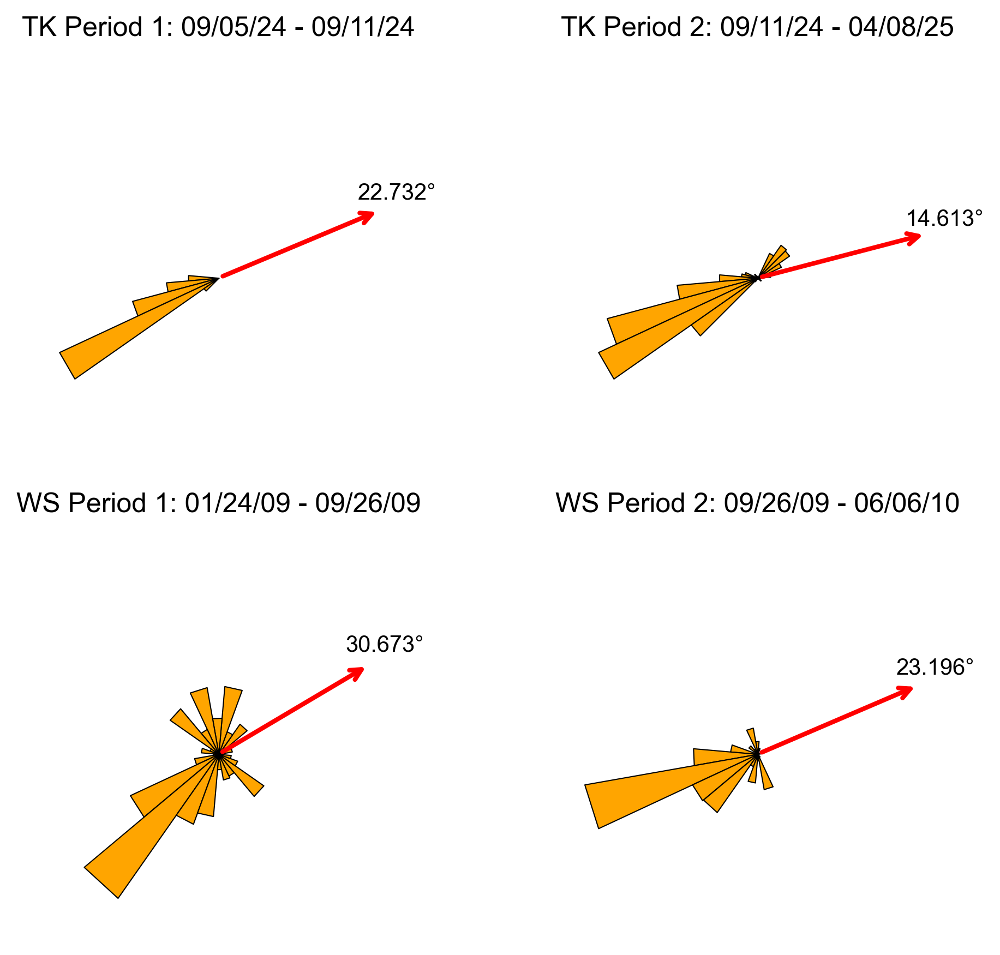

In [10]:
# TK
dw_tk = pd.read_excel('/Users/ylin0188/Desktop/code box/dfsframework code/wind_general.xlsx', sheet_name='TK')
dw_tk = dw_tk.set_index('Time').resample('1h').mean().reset_index()

time1tk = pd.Timestamp('2024-09-05 15:26:00')
time2tk = pd.Timestamp('2024-09-11 11:19:00')
time3tk = pd.Timestamp('2025-04-08 12:58:00')

dw_tk1 = dw_tk[(dw_tk.Time >= time1tk) & (dw_tk.Time <= time2tk)].copy()
dw_tk2 = dw_tk[(dw_tk.Time >= time2tk) & (dw_tk.Time <= time3tk)].copy()

z01_tk = 1.5
af0_tk = 15

def process_dw(dw):
    time_col = dw.columns[0]
    wind_dir_col = dw.columns[1]
    wind_speed_col = dw.columns[2]
    dw = dw.rename(columns={time_col:'time', wind_dir_col: 'wind_direction', wind_speed_col: 'wind_speed'})
    dw['time'] = pd.to_datetime(dw['time'])
    dw['speed'] = pd.to_numeric(dw['wind_speed'], errors='coerce')
    dw['direction'] = pd.to_numeric(dw['wind_direction'], errors='coerce')
    dw = dw.drop(['wind_speed', 'wind_direction'], axis=1)
    return dw

dw_tk1 = process_dw(dw_tk1)
dw_tk2 = process_dw(dw_tk2)

# WS
dw_ws = pd.read_excel('/Users/ylin0188/Desktop/code box/dfsframework code/wind_general.xlsx', sheet_name='WS')
time_col = dw_ws.columns[0]
wind_dir_col = dw_ws.columns[1]
wind_speed_col = dw_ws.columns[2]
dw_ws = dw_ws.rename(columns={time_col:'time', wind_dir_col: 'wind_direction', wind_speed_col: 'wind_speed'})
dw_ws['time'] = pd.to_datetime(dw_ws['time'])
dw_ws['speed'] = pd.to_numeric(dw_ws['wind_speed'], errors='coerce')
dw_ws['direction'] = pd.to_numeric(dw_ws['wind_direction'], errors='coerce')
dw_ws = dw_ws.drop(['wind_speed', 'wind_direction'], axis=1)

time0 = pd.Timestamp(dfws.t[0].item()).tz_localize('UTC')
time1 = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')
time2 = pd.Timestamp(dfws.t[2].item()).tz_localize('UTC')

dwws_period1 = dw_ws[(dw_ws.time >= time0) & (dw_ws.time <= time1)].dropna()
dwws_period2 = dw_ws[(dw_ws.time >= time1) & (dw_ws.time <= time2)].dropna()

z01_ws = 10
af0_ws = 25
da_ws = 15

# draw flux rose plot
def plot_rose_tk(ax, dw, title):
    da = 10
    mAf = np.arange(-180, 180 + da, da)
    mAmidf = mAf[1:] - da / 2
    
    uKHMN = dw.speed
    qKHMN = flux(uKHMN, z01_tk, z00, rhos_tk)
    aKHMN = bearing_2_pm180_af0(dw.direction, af0_tk)
    
    pq2aa = np.empty(len(mAmidf))
    for i in range(len(mAmidf)):
        pq2aa[i] = np.sum(qKHMN[(aKHMN >= mAf[i]) & (aKHMN < mAf[i + 1])])
    pq2aa = pq2aa / np.sum(qKHMN)
    
    for i in range(len(mAmidf)):
        ax.fill_between([(mAf[i] + af0_tk) / 180 * np.pi + np.pi, 
                         (mAf[i + 1] + af0_tk) / 180 * np.pi + np.pi], 
                        pq2aa[i], lw=0.5, edgecolor='k', facecolor='orange')
    
    theta_center_deg = np.array([(mAf[i] + mAf[i + 1]) / 2 for i in range(len(mAmidf))])
    theta_center_rad = (theta_center_deg + af0_tk) / 180 * np.pi + np.pi
    vector_sum = np.sum(pq2aa * np.exp(1j * theta_center_rad))
    dominant_rad = np.angle(vector_sum)
    max_r = max(pq2aa)
    ax.annotate('', xy=(dominant_rad + np.pi, max_r), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='red', lw=2))
    dominant_deg = (dominant_rad / np.pi * 180 + 180) % 360
    ax.text(dominant_rad + np.pi, max_r * 1.1, f'{dominant_deg:.3f}°',
            ha='center', va='bottom', fontsize=10)
    ax.axis('off')
    ax.set_title(title, fontsize=12)

def plot_rose_ws(ax, dw, title):
    da = 15
    mAf = np.arange(-180, 180 + da, da)
    mAmidf = mAf[1:] - da / 2
    
    uKHMN = dw.speed
    qKHMN = flux(uKHMN, z01_ws, z00, rhos_tk)
    aKHMN = bearing_2_pm180_af0(dw.direction, af0_ws)
    
    pq2aa = np.empty(len(mAmidf))
    for i in range(len(mAmidf)):
        pq2aa[i] = np.sum(qKHMN[(aKHMN >= mAf[i]) & (aKHMN < mAf[i + 1])])
    pq2aa = pq2aa / np.sum(qKHMN)
    
    for i in range(len(mAmidf)):
        ax.fill_between([(mAf[i] + af0_ws) / 180 * np.pi + np.pi, 
                         (mAf[i + 1] + af0_ws) / 180 * np.pi + np.pi], 
                        pq2aa[i], lw=0.5, edgecolor='k', facecolor='orange')
    
    theta_center_deg = np.array([(mAf[i] + mAf[i + 1]) / 2 for i in range(len(mAmidf))])
    theta_center_rad = (theta_center_deg + af0_ws) / 180 * np.pi + np.pi
    vector_sum = np.sum(pq2aa * np.exp(1j * theta_center_rad))
    dominant_rad = np.angle(vector_sum)
    max_r = max(pq2aa)
    ax.annotate('', xy=(dominant_rad + np.pi, max_r), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='red', lw=2))
    dominant_deg = (dominant_rad / np.pi * 180 + 180) % 360
    ax.text(dominant_rad + np.pi, max_r * 1.1, f'{dominant_deg:.3f}°',
            ha='center', va='bottom', fontsize=10)
    ax.axis('off')
    ax.set_title(title, fontsize=12)

fig, axes = plt.subplots(2, 2, figsize=(7, 6), subplot_kw={'projection': 'polar'})

plot_rose_tk(axes[0, 0], dw_tk1, f'TK Period 1: {time1tk.strftime("%m/%d/%y")} - {time2tk.strftime("%m/%d/%y")}')
plot_rose_tk(axes[0, 1], dw_tk2, f'TK Period 2: {time2tk.strftime("%m/%d/%y")} - {time3tk.strftime("%m/%d/%y")}')

plot_rose_ws(axes[1, 0], dwws_period1, f'WS Period 1: {time0.strftime("%m/%d/%y")} - {time1.strftime("%m/%d/%y")}')
plot_rose_ws(axes[1, 1], dwws_period2, f'WS Period 2: {time1.strftime("%m/%d/%y")} - {time2.strftime("%m/%d/%y")}')

plt.tight_layout()
plt.show()

In [11]:
def process_wind_data(file_path, start_time, end_time, af0):
    dwtk = pd.read_excel(file_path, sheet_name='TK')
    
    cols = dwtk.columns[:3]
    dwtk = dwtk.rename(columns={cols[0]: 'time', cols[1]: 'wind_direction', cols[2]: 'wind_speed'})
    
    dwtk['time'] = pd.to_datetime(dwtk['time'])
    dwtk['speed'] = pd.to_numeric(dwtk['wind_speed'], errors='coerce')
    dwtk['direction'] = pd.to_numeric(dwtk['wind_direction'], errors='coerce')
    dwtk = dwtk.drop(['wind_speed', 'wind_direction'], axis=1)
    
    dwtk['time'] = dwtk['time'].dt.tz_localize('UTC')
    dwtk = dwtk[(dwtk.time >= start_time) & (dwtk.time <= end_time)].dropna()
    
    dwtk['direction_af0'] = bearing_2_pm180_af0(dwtk['direction'], af0)
    dwtk['speed_proj'] = dwtk.speed * np.cos(np.abs(np.deg2rad(dwtk['direction_af0'])))
    
    dwtk_hourly = dwtk.resample('1h', on='time').mean().reset_index()
    dwtk_hourly['direction_af0'] = bearing_2_pm180_af0(dwtk_hourly['direction'], af0)
    dwtk_hourly['speed_proj'] = dwtk_hourly.speed * np.cos(np.abs(np.deg2rad(dwtk_hourly['direction_af0'])))
    
    return dwtk, dwtk_hourly


file_path = '/Users/ylin0188/Desktop/code box/dfsframework code/wind_general.xlsx'


start1 = pd.Timestamp('2024-09-05 15:26:00').tz_localize('UTC')
end1 = pd.Timestamp('2024-09-11 11:19:00').tz_localize('UTC')
dwtk0, dwtk_hourly0 = process_wind_data(file_path, start1, end1, 22.732)

start2 = pd.Timestamp('2024-09-11 11:19:00').tz_localize('UTC')
end2 = pd.Timestamp('2025-04-08 12:58:00').tz_localize('UTC')
dwtk1, dwtk_hourly1 = process_wind_data(file_path, start2, end2, 14.613)

In [12]:
dwws = pd.read_excel('/Users/ylin0188/Desktop/code box/dfsframework code/wind_general.xlsx', sheet_name='WS')
dwws['direction']=dwws.Direction
dwws['time'] = pd.to_datetime(dwws['Time'])
dwws = dwws.set_index('time')
dwws = dwws.to_xarray()

time0 = pd.Timestamp(dfws.t[0].item()).tz_localize('UTC')
time1 = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')
time2 = pd.Timestamp(dfws.t[2].item()).tz_localize('UTC')

dwws_period1 = dwws.where((dwws.time >= time0) & (dwws.time <= time1), drop=True)
dwws_period2 = dwws.where((dwws.time >= time1) & (dwws.time <= time2), drop=True)
dwws_period1['direction_af0']=('time',bearing_2_pm180_af0(dwws_period1['direction'],30.673))
dwws_period1['speed_proj']=dwws_period1.Speed*np.cos(np.abs(np.deg2rad(dwws_period1['direction_af0'])))
dwws_period2['direction_af0']=('time',bearing_2_pm180_af0(dwws_period2['direction'],23.196))
dwws_period2['speed_proj']=dwws_period2.Speed*np.cos(np.abs(np.deg2rad(dwws_period2['direction_af0'])))

dwws_daily1 = dwws_period1.resample(time='1D').mean()
dwws_df1 = dwws_period1.to_dataframe().reset_index()
dwws_daily_df1 = dwws_daily1.to_dataframe().reset_index()

dwws_daily2 = dwws_period2.resample(time='1D').mean()
dwws_df2 = dwws_period2.to_dataframe().reset_index()
dwws_daily_df2 = dwws_daily2.to_dataframe().reset_index()

In [13]:
dunemask_data = (dftk.zs[0]-dftk.zs[0].min()).T.values
contours = measure.find_contours(dunemask_data, level=2.8)
xmin=dftk.x.min()
ymin=dftk.y.min()


if contours:
    max_area = 0
    largest_contour = None
    
    for contour in contours:
        x_vals = contour[:, 1]
        y_vals = contour[:, 0]
        area = 0.5 * np.abs(np.dot(x_vals, np.roll(y_vals, 1)) - np.dot(y_vals, np.roll(x_vals, 1)))
        
        if area > max_area:
            max_area = area
            largest_contour = contour
    
    if largest_contour is not None:
        X = np.linspace(float(x[0]-xmin), float(x[-1]-xmin), dunemask_data.shape[1])
        Y = np.linspace(float(y[0]-ymin), float(y[-1]-ymin), dunemask_data.shape[0])

Text(0.02, 0.95, 'F')

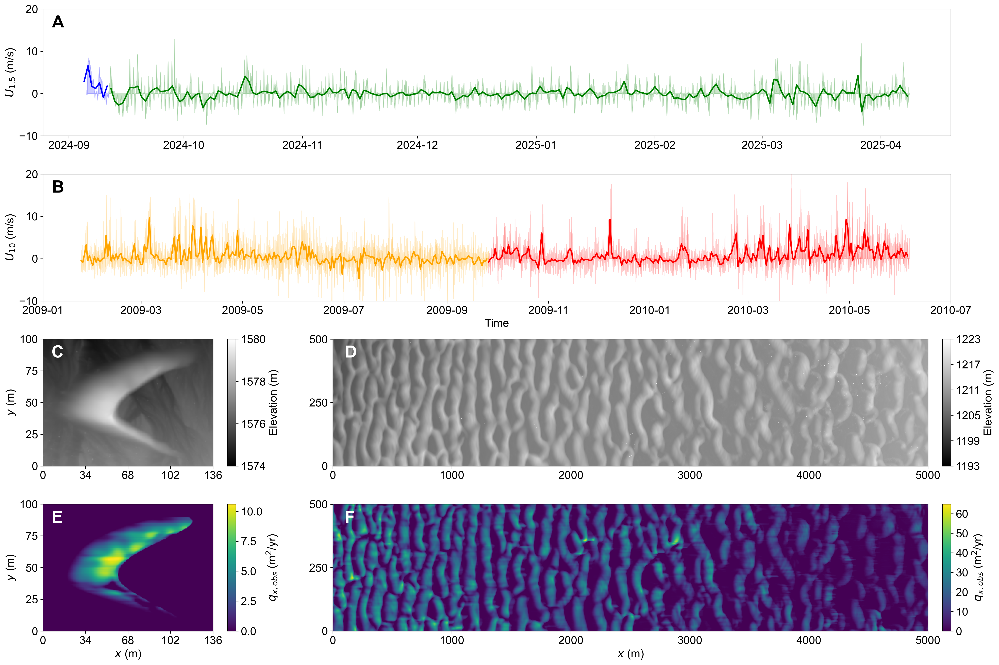

In [24]:
fontsize = 16
fs=8
plt.rcParams.update({'font.size': fontsize})
fig = plt.figure(figsize=(24, 16))
gs = gridspec.GridSpec(
    4, 6,                
    width_ratios=[10, 0.5, 4, 35, 0.5, 1], 
    height_ratios=[1, 1,1,1],        
    wspace=0.1, hspace=0.3
)

ax_wind0=plt.subplot(gs[0, 0:5])
dwtk_combined = pd.concat([dwtk_hourly0, dwtk_hourly1], ignore_index=True)
dw_daily = dwtk_combined.resample('1d', on='time').mean().reset_index()
mask1 = dw_daily['time'] <= dwtk_hourly0['time'].max()
mask2 = dw_daily['time'] >= dwtk_hourly1['time'].min()
dw_daily0 = dw_daily[mask1]
dw_daily1 = dw_daily[mask2]
ax_wind0.plot(dw_daily0['time'], dw_daily0['speed_proj'], color='blue', lw=2)
ax_wind0.plot(dw_daily1['time'], dw_daily1['speed_proj'], color='green', lw=2)
ax_wind0.fill_between(dwtk_hourly0['time'], dwtk_hourly0['speed_proj'],
                      color='blue', alpha=0.2, label='Period 1')
ax_wind0.fill_between(dwtk_hourly1['time'], dwtk_hourly1['speed_proj'],
                      color='green', alpha=0.2, label='Period 2')
ax_wind0.set_ylim(-10, 20)
ax_wind0.set_xlabel('')
ax_wind0.set_ylabel('$U_{1.5}$ (m/s)')



ax_wind1=plt.subplot(gs[1, 0:5])
ax_wind1.fill_between(dwws_df1['time'], dwws_df1['speed_proj'], color='orange', alpha=0.2)
ax_wind1.plot(dwws_daily_df1['time'], dwws_daily_df1['speed_proj'], color='orange', lw=2)
ax_wind1.fill_between(dwws_df2['time'], dwws_df2['speed_proj'], color='red', alpha=0.2)
ax_wind1.plot(dwws_daily_df2['time'], dwws_daily_df2['speed_proj'], color='red', lw=2)
ax_wind1.set_xlim(pd.Timestamp('2009-01-01'), pd.Timestamp('2010-07-01'))
ax_wind1.set_ylim(-10, 20)
ax_wind1.set_xlabel('Time')
ax_wind1.set_ylabel('$U_{10}$ (m/s)')

ax0 = plt.subplot(gs[2, 0])
cx0 = plt.subplot(gs[2, 1])
im = ax0.pcolormesh(X, Y, (dftk.zs[2].T.values), cmap='grey',vmin=1574,vmax=1580)
plt.colorbar(im, cax=cx0,label='Elevation (m)')
ax0.set_xlabel('')
ax0.set_xlim(0,136)
ax0.set_xticks([0, 34, 68, 102, 136])
ax0.set_xticklabels(['0', '34', '68','102', '136'])
ax0.set_ylabel('$y$ (m)')
ax0.set_ylim(0,100)
ax0.set_yticks([0, 25, 50, 75, 100])
ax0.set_yticklabels(['0', '25', '50', '75', '100'])



ax1 = plt.subplot(gs[2, 3])
cx1 = plt.subplot(gs[2, 4])
dfws.z[1].T.plot(ax=ax1, cmap='grey',cbar_ax=cx1,vmin=1193,vmax=1223,
                  cbar_kwargs={'ticks': np.linspace(1193, 1223, 6),'label': 'Elevation (m)'})
plt.title('')
ax1.set_xlim(0,5000)
ax1.set_xticks([0,1000, 2000, 3000, 4000, 5000])
ax1.set_xticklabels([0,1000, 2000, 3000, 4000, 5000])
ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.set_title('')
ax1.set_yticks([0, 250, 500])
ax1.set_yticklabels(['0', '250', '500'])

ax2 = plt.subplot(gs[3, 0])
cx2 = plt.subplot(gs[3, 1])
im = ax2.pcolormesh(X, Y, (dftk.qmask[1].T.values), cmap='viridis')
cbar=plt.colorbar(im, cax=cx2,label='$q_{x,obs}$ (m$^{2}$/yr)')
ax2.set_xlabel('$x$ (m)')
ax2.set_xlim(0,136)
ax2.set_xticks([0, 34, 68, 102, 136])
ax2.set_xticklabels(['0', '34', '68','102', '136'])
ax2.set_ylabel('$y$ (m)')
ax2.set_ylim(0,100)
ax2.set_yticks([0, 25, 50, 75, 100])
ax2.set_yticklabels(['0', '25', '50', '75', '100'])

ax3 = plt.subplot(gs[3, 3])
cx3 = plt.subplot(gs[3, 4])
dfws.qre[1].T.plot(ax=ax3, cmap='viridis',cbar_ax=cx3,vmin=0,
                  cbar_kwargs={'ticks': np.linspace(0, 60, 7),'label': '$q_{x,obs}$ (m$^{2}$/yr)'})
plt.title('')
ax3.set_xlim(0,5000)
ax3.set_yticks([0, 250, 500])
ax3.set_yticklabels(['0', '250', '500'])
ax3.set_xlabel('$x$ (m)')
ax3.set_ylabel('')
ax3.set_title('')


ax_wind0.text(0.01, 0.95, "A", transform=ax_wind0.transAxes, fontsize=fs*3, fontweight='bold', va='top')
ax_wind1.text(0.01, 0.95, "B", transform=ax_wind1.transAxes, fontsize=fs*3, fontweight='bold', va='top')
ax0.text(0.05, 0.95, "C", transform=ax0.transAxes, fontsize=fs*3, fontweight='bold', va='top',color='w')
ax1.text(0.02, 0.95, "D", transform=ax1.transAxes, fontsize=fs*3, fontweight='bold', va='top',color='w')
ax2.text(0.05, 0.95, "E", transform=ax2.transAxes, fontsize=fs*3, fontweight='bold', va='top',color='w')
ax3.text(0.02, 0.95, "F", transform=ax3.transAxes, fontsize=fs*3, fontweight='bold', va='top',color='w')

# Figure 3

In [29]:
# process DEM+wind data in the White Sands to get field-resolved wind and sediment flux

af0 = 25 # for white sands from Gunn et al. 2020
z01 = 10 # wind speed is measured at 10 m from KHMN station in the mestwest dataset
adelta = 15
start_time = pd.Timestamp(dfws.t[1].item()).tz_localize('UTC')
end_time = pd.Timestamp(dfws.t[2].item()).tz_localize('UTC')

zdata=dfws.zre[1].values[3000:8000,:] # in order to save computational cost

dtws = xr.Dataset(data_vars=dict(z=(['x','y'],zdata)),
                coords=dict(x=(['x'],np.arange(zdata.shape[0])),
                            y=(['y'],np.arange(zdata.shape[1]))))

# use the represenstative/best values from the optimization method
ut = 0.32
Cq = 4.5
lsat = 1.7
padsl = -1/6
recth = np.tan(-18*np.pi/180)
recsl = -1/6

dtws = make_pad(dtws,'z','zp',padsl)
dtws = make_bubble(dtws,'zp','zb',recth,recsl)
# dtws = dtws.coarsen(x=2, y=2, boundary='pad').mean()

In [30]:
dw_period1 = dwws_df2[
    (dwws_df2.time >= start_time) & 
    (dwws_df2.time <= end_time) & 
    (dwws_df2.speed_proj * kap / np.log(10 / z00) >= ut)
].dropna()

dw_period1['stree_velocity'] = dw_period1['Speed']*kap/np.log(z01/z00)

us=dw_period1['stree_velocity'].mean().item()#representative value e.g. mean value

dtws['uxso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dtws.x.data,dtws.y.data,dtws.zb.where(~dtws.zb.isnull(),dtws.zp).data,d,us,nu),us).real)
dtws['uxs'] = dtws.uxso.where(dtws.zb.isnull(),np.nan)
dtws['uxso_neg'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dtws.x.data,dtws.y.data,dtws.zb.where(~dtws.zb.isnull(), dtws.zp).data[::-1, ::-1],d,us,nu),us).real)
dtws['uxs_neg'] = dtws.uxso_neg.where(dtws.zb.isnull(),np.nan)
dtws['uyso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dtws.x.data,dtws.y.data,dtws.zb.where(~dtws.zb.isnull(),dtws.zp).data,d,us,nu),us).imag)
dtws['uys'] = dtws.uyso.where(dtws.zb.isnull(),np.nan)

dtws = dtws.assign_coords(time=dw_period1.time)
dtws['ux'] = (('time'),dw_period1['stree_velocity'])
dtws['uxt_positive'] = dtws.ux.where(dtws.ux >= 0) / us * dtws.uxs
dtws['uxt_negative'] = (-np.abs(dtws.ux.where(dtws.ux <= 0)) / us * dtws.uxs_neg)[::-1, ::-1]  # rotate after calculation
dtws['uxt'] = dtws.uxt_positive.fillna(0)
dtws['uxspt'] = dtws.uxt.mean('time')
dtws['qs'] = (dtws.uxt**2-ut**2)*Cq*ut*rhof/rhos_ws*grav
dtws['qs'] = dtws.qs.where(dtws.qs>0,0)
dtws['qsat'] = dtws.qs.mean('time') * 365.25 * 24

dtws['qs'] = dtws.qs[:,
    int((dtws.uxspt.shape[0]-5000)/2):int((dtws.uxspt.shape[0]-5000)/2+5000),
    int((dtws.uxspt.shape[1]-501)/2):int((dtws.uxspt.shape[1]-501)/2+501)
].where(dfws.qre[1, 3000:8000, :] > 2, other=0)
dtws['qs'] = dtws.qs.fillna(0)
# dtws['qsat'] = dtws.qs.mean('time') * 365.25 * 24
q = np.zeros(dtws.qs.shape) # true flux array initialised
q[:,0] = 0 # input true flux at x=0, here just arbitrary
dx=dtws.x.isel(x=slice(None,2)).diff('x').data[0]
for i in range(1,q.shape[1]):
    q[:,i] = (q[:,i-1]+dx*dtws.qs.data[:,i]/lsat)/(1+dx/lsat) # loop through and make true flux
dtws['q'] = (('time','x','y'),q)
dtws['qspt'] = dtws.q.mean('time') * 365.25 * 24

In [25]:
start_time = pd.Timestamp(dftk.time[1].item()).tz_localize('UTC')
end_time = pd.Timestamp(dftk.time[2].item()).tz_localize('UTC')

dttk = xr.Dataset(
    {
        'z': (('x', 'y'),gaussian_filter((dftk.dunemask[1] - dftk.dunemask[1].min()).
                                         fillna(0).values.astype(float), sigma=8))
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dttk = make_pad(dttk,'z','zp',padsl)
dttk= make_bubble(dttk,'zp','zb',recth,recsl)
dttk['zpb'] = xr.where(dttk.zb.isnull(), dttk.zp, dttk.zb)
dttk['zpbro'] = dttk.zpb-dttk.zp+dttk.z
qdata=dftk.qmask[1].values
qdem = np.zeros(dttk.z.shape)
x_offset = (dttk.x.size- qdata.shape[0]) // 2
y_offset = (dttk.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dttk['qdem'] = (('x','y'),qdem)

ut = 0.3
Cq = 6
lsat = 1.5
z01 = 1.5
dw_period1 = dwtk_hourly1.where((dwtk_hourly1.time >= start_time) & (dwtk_hourly1.time <= end_time) & (dwtk_hourly1.speed*kap/np.log(z01/z00) >=ut))
dw_period1['stree_velocity'] = dw_period1['speed']*kap/np.log(z01/z00)
dw_period1 = dw_period1.dropna()

us=dw_period1['stree_velocity'].mean()#representative value
dttk['uxso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dttk.x.data,dttk.y.data,dttk.zb.where(~dttk.zb.isnull(),dttk.zp).data,d,us,nu),us).real)
dttk['uxs'] = dttk.uxso.where(dttk.zb.isnull(),np.nan)
dttk['uyso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dttk.x.data,dttk.y.data,dttk.zb.where(~dttk.zb.isnull(),dttk.zp).data,d,us,nu),us).imag)
dttk['uys'] = dttk.uyso.where(dttk.zb.isnull(),np.nan)

dttk = dttk.assign_coords(time=dw_period1.time)
dttk['ux'] = (('time'),dw_period1['stree_velocity'])
dttk['uxt'] = dttk.ux/us*dttk.uxs
dttk['qs'] = (dttk.uxt**2-ut**2)*Cq*ut*rhof/rhos_tk*grav
dttk['qs'] = dttk.qs.where(dttk.qs>0,0)

dttk['qsat'] = dttk.qs.mean('time') * 365.25 * 24

dx = dttk.x.isel(x=slice(None,2)).diff('x').data[0]

q = np.zeros(dttk.qs.shape) # true flux array initialised
q[:,0] = 0 # input true flux at x=0, here just arbitrary
dx=dttk.x.isel(x=slice(None,2)).diff('x').data[0]
for i in range(1,q.shape[1]):
    q[:,i] = (q[:,i-1]+dx*dttk.qs.data[:,i]/lsat)/(1+dx/lsat) # loop through and make true flux
dttk['q'] = (('time','x','y'),q)
dttk['qspt'] = dttk.q.mean('time') * 365.25 * 24
dttk1 = dttk.copy()
dttk1['qspt'] = (('x', 'y'), np.nan_to_num(dftk.mask.values * dttk.qspt.values, nan=0.0))


dttk = xr.Dataset(
    {
        'z': (('x', 'y'),gaussian_filter((dftk.dunemask[1] - dftk.dunemask[1].min()).
                                         fillna(0).values.astype(float), sigma=3))
    },
    coords={
        'x': (('x'), dftk.x.values - dftk.x.min().item()),
        'y': (('y'), dftk.y.values - dftk.y.min().item()),
    },
)

dttk = make_pad(dttk,'z','zp',padsl)
dttk= make_bubble(dttk,'zp','zb',recth,recsl)
dttk['zpb'] = xr.where(dttk.zb.isnull(), dttk.zp, dttk.zb)
dttk['zpbro'] = dttk.zpb-dttk.zp+dttk.z
qdata=dftk.qmask[1].values
qdem = np.zeros(dttk.z.shape)
x_offset = (dttk.x.size- qdata.shape[0]) // 2
y_offset = (dttk.y.size- qdata.shape[1]) // 2
qdem[x_offset:x_offset + qdata.shape[0], y_offset:y_offset + qdata.shape[1]] = qdata
dttk['qdem'] = (('x','y'),qdem)

ut = 0.25
Cq = 6
lsat = 0.8
z01=1.5
dw_period1 = dwtk_hourly1.where((dwtk_hourly1.time >= start_time) & (dwtk_hourly1.time <= end_time) & (dwtk_hourly1.speed*kap/np.log(z01/z00) >=ut))
dw_period1['stree_velocity'] = dw_period1['speed']*kap/np.log(z01/z00)
dw_period1 = dw_period1.dropna()

us=dw_period1['stree_velocity'].mean()#representative value
dttk['uxso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dttk.x.data,dttk.y.data,dttk.zb.where(~dttk.zb.isnull(),dttk.zp).data,d,us,nu),us).real)
dttk['uxs'] = dttk.uxso.where(dttk.zb.isnull(),np.nan)
dttk['uyso'] = (('x','y'),get_usxy_xy(get_taupxy_xy(dttk.x.data,dttk.y.data,dttk.zb.where(~dttk.zb.isnull(),dttk.zp).data,d,us,nu),us).imag)
dttk['uys'] = dttk.uyso.where(dttk.zb.isnull(),np.nan)

Text(0.01, 0.95, 'F')

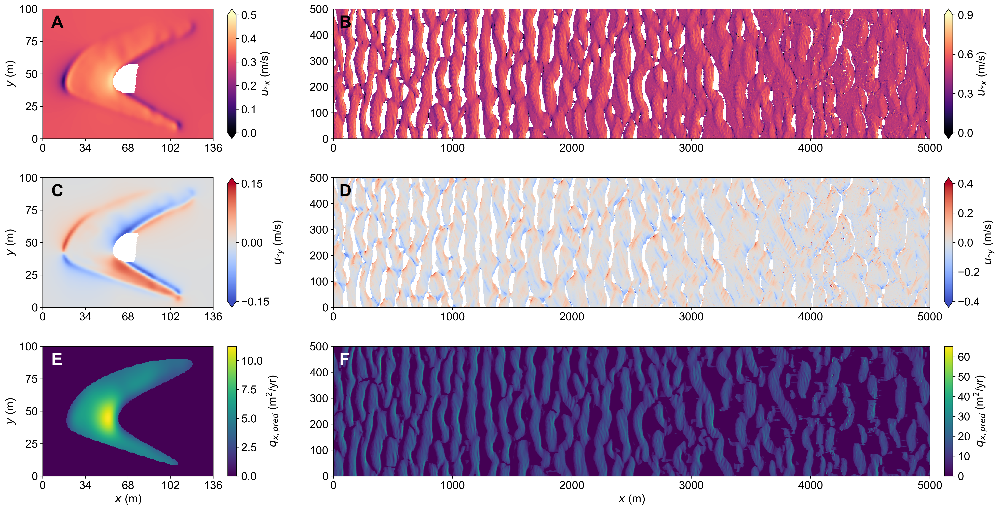

In [31]:
fig = plt.figure(figsize=(24,12))
gs = gridspec.GridSpec(
    3, 6,                
    width_ratios=[10, 0.5, 4, 35, 0.5, 1], 
    height_ratios=[1, 1, 1],        
    wspace=0.1, hspace=0.3 
)

ax0 = plt.subplot(gs[0, 0])
cx0 = plt.subplot(gs[0, 1])
im = ax0.pcolormesh(X, Y, (dttk.uxs.T.values), cmap='magma',vmax=0.5,vmin=0)
cbar=plt.colorbar(im, cax=cx0,label='$u_{*x}$ (m/s)',extend='both')
cbar.set_ticks(np.linspace(0, 0.5, 6))
ax0.set_xlim(0,136)
ax0.set_xticks([0, 34, 68, 102, 136])
ax0.set_xticklabels(['0', '34', '68','102', '136'])
ax0.set_xlabel('')
ax0.set_ylabel('$y$ (m)')
ax0.set_ylim(0,100)
ax0.set_yticks([0, 25, 50, 75, 100])
ax0.set_yticklabels(['0', '25', '50', '75', '100'])

ax1 = plt.subplot(gs[0, 3])
cx1 = plt.subplot(gs[0, 4])
dtws.uxs[int((dtws.uxspt.shape[0]-5000)/2):int((dtws.uxspt.shape[0]-5000)/2+5000)
        ,int((dtws.uxspt.shape[1]-500)/2):int((dtws.uxspt.shape[1]-500)/2+500)].T.plot(ax=ax1, cmap='magma',cbar_ax=cx1,vmin=0,vmax=0.9,
                                                                                       cbar_kwargs={'ticks': np.linspace(0, 0.9, 4),'label': '$u_{*x}$ (m/s)'})
plt.title('')
ax1.set_xlim(0,5000)
ax1.set_xticks([0, 1000, 2000, 3000, 4000, 5000])
ax1.set_xticklabels([0, 1000, 2000, 3000, 4000, 5000])
ax1.set_ylim(0,500)
ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.set_title('')

ax2 = plt.subplot(gs[1, 0])
cx2 = plt.subplot(gs[1, 1])
im = ax2.pcolormesh(X, Y, (dttk.uys.T.values), cmap='coolwarm',vmin=-0.15,vmax=0.15)
cbar=plt.colorbar(im, cax=cx2,label='$u_{*y}$ (m/s)',extend='both') 
cbar.set_ticks(np.linspace(-0.15, 0.15, 3))
ax2.set_xlim(0,136)
ax2.set_xticks([0, 34, 68, 102, 136])
ax2.set_xticklabels(['0', '34', '68','102', '136'])
ax2.set_xlabel('')
ax2.set_ylabel('$y$ (m)')
ax2.set_ylim(0,100)
ax2.set_yticks([0, 25, 50, 75, 100])
ax2.set_yticklabels(['0', '25', '50', '75', '100'])



ax3 = plt.subplot(gs[1, 3])
cx3 = plt.subplot(gs[1, 4])
dtws.uys[int((dtws.uxspt.shape[0]-5000)/2):int((dtws.uxspt.shape[0]-5000)/2+5000)
        ,int((dtws.uxspt.shape[1]-500)/2):int((dtws.uxspt.shape[1]-500)/2+500)].T.plot(ax=ax3, cmap='coolwarm',cbar_ax=cx3,vmin=-0.4,vmax=0.4,
                                                                                       cbar_kwargs={'ticks': np.linspace(-0.4, 0.4 , 5),'label': '$u_{*y}$ (m/s)'})
plt.title('')
ax3.set_xlim(0,5000)
ax3.set_xticks([0, 1000, 2000, 3000, 4000, 5000])
ax3.set_xticklabels([0, 1000, 2000, 3000, 4000, 5000])
ax3.set_ylim(0,500)
ax3.set_xlabel('')
ax3.set_ylabel('')
ax3.set_title('')

ax4 = plt.subplot(gs[2, 0])
cx4 = plt.subplot(gs[2, 1])



im = ax4.pcolormesh(X, Y, (dttk1.qspt.T.values), cmap='viridis')

cbar=plt.colorbar(im, cax=cx4,label='$q_{x,pred}$ (m$^{2}$/yr)')
ax4.set_xlim(0,136)
ax4.set_xticks([0, 34, 68, 102, 136])
ax4.set_xticklabels(['0', '34', '68','102', '136'])
ax4.set_xlabel('$x$ (m)')
ax4.set_ylabel('$y$ (m)')
ax4.set_ylim(0,100)
ax4.set_yticks([0, 25, 50, 75, 100])
ax4.set_yticklabels(['0', '25', '50', '75', '100'])

ax5 = plt.subplot(gs[2, 3])
cx5 = plt.subplot(gs[2, 4])
dtws.qspt[int((dtws.uxspt.shape[0]-5000)/2):int((dtws.uxspt.shape[0]-5000)/2+5000)
        ,int((dtws.uxspt.shape[1]-501)/2):int((dtws.uxspt.shape[1]-501)/2+501)].T.plot(ax=ax5, cmap='viridis',cbar_ax=cx5,vmin=0,
                                                                                       cbar_kwargs={'ticks': np.linspace(0, 60, 7),'label': '$q_{x,pred}$ (m$^{2}$/yr)'})
plt.title('')
ax5.set_xlim(0,5000)
ax5.set_ylim(0,500)
ax5.set_xlabel('$x$ (m)')
ax5.set_ylabel('')
ax5.set_title('')

ax0.text(0.05, 0.95, "A", transform=ax0.transAxes, fontsize=fs*3, fontweight='bold', va='top')
ax1.text(0.01, 0.95, "B", transform=ax1.transAxes, fontsize=fs*3, fontweight='bold', va='top')
ax2.text(0.05, 0.95, "C", transform=ax2.transAxes, fontsize=fs*3, fontweight='bold', va='top')
ax3.text(0.01, 0.95, "D", transform=ax3.transAxes, fontsize=fs*3, fontweight='bold', va='top')
ax4.text(0.05, 0.95, "E", transform=ax4.transAxes, fontsize=fs*3, fontweight='bold', va='top',color='w')
ax5.text(0.01, 0.95, "F", transform=ax5.transAxes, fontsize=fs*3, fontweight='bold', va='top',color='w')